# MNIST Classification (Embedded)

Loads MNIST via scikit-learn's `fetch_openml`, trains a simple MLP classifier with PyTorch Lightning, and evaluates on the held-out test set.

Note: Notebook use the dev dependencies to run, use `uv sync --all-extras` to setup dev-virtual environment

In [41]:
import numpy as np
import matplotlib.pyplot as plt
from copy import deepcopy
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader, random_split
import lightning as L
from torchmetrics import Accuracy
from sklearn.datasets import fetch_openml

L.seed_everything(42)

Seed set to 42


42

## Load MNIST

`fetch_openml` downloads and caches the dataset on first run. `mnist_784` preserves the original
MNIST ordering, so the first 60,000 rows are the standard train split and the last 10,000 are the
standard test split.

In [42]:
mnist = fetch_openml('mnist_784', version=1, as_frame=False, parser='liac-arff')
X, y = mnist.data, mnist.target.astype(np.int64)

X_train_full, y_train_full = X[:60000], y[:60000]
X_test, y_test = X[60000:], y[60000:]

print(X_train_full.shape, y_train_full.shape, X_test.shape, y_test.shape)

(60000, 784) (60000,) (10000, 784) (10000,)


## Normalize and build datasets

Pixel values are cast from `float64` in `[0, 255]` to `float32` in `[0, 1]`. The 60,000-row train
pool is split into train/validation subsets.

In [43]:
X_train_full = (X_train_full / 255.0).astype(np.float32)
X_test = (X_test / 255.0).astype(np.float32)

full_ds = TensorDataset(torch.from_numpy(X_train_full), torch.from_numpy(y_train_full))
test_ds = TensorDataset(torch.from_numpy(X_test), torch.from_numpy(y_test))

val_size = 6000
train_ds, val_ds = random_split(
    full_ds, [len(full_ds) - val_size, val_size],
    generator=torch.Generator().manual_seed(42),
)

len(train_ds), len(val_ds), len(test_ds)

(54000, 6000, 10000)

## Sanity check: visualize a few training digits

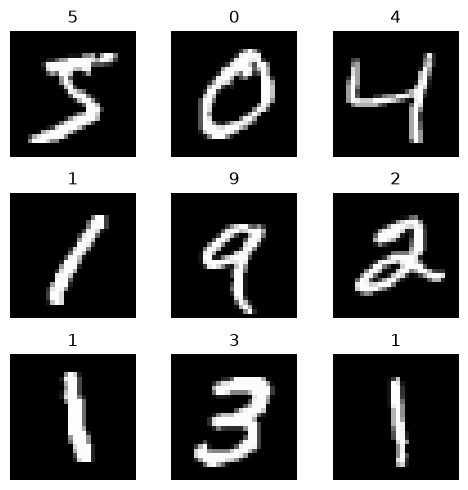

In [44]:
fig, axes = plt.subplots(3, 3, figsize=(5, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(X_train_full[i].reshape(28, 28), cmap='gray')
    ax.set_title(str(y_train_full[i]))
    ax.axis('off')
plt.tight_layout()
plt.show()

## DataLoaders

In [45]:
BATCH_SIZE = 128

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

## CNN with Taylor Prunning

A minimal CNN. Each `ConvBlock` is a single
`Conv2d (zero padding) -> BatchNorm2d`, added to a skip connection (identity, or a `1x1`
projection when channels change), followed by `ReLU`. The flattened `(N, 784)` input is
reshaped to `(N, 1, 28, 28)` inside the model so the rest of the pipeline (DataLoaders,
calibration reader, ONNX export) doesn't need to change.

Structure:
- CNN Network with network wide `prune` and `compact` methods
   - Custom CNN Blocks with layer wide `prune` and `compact` methods
      - Taylor Pruning method called in invidual layers

`prune` is called during training
`compact` post training by applying the prunning mask to the network to reduce its foot-print

In [46]:
import torch.nn.utils.prune as prune

class TaylorStructured(prune.BasePruningMethod):

    PRUNING_TYPE = "structured"
 
    def __init__(self, amount, dim=0):
        self.amount = amount
        self.dim = dim

    @staticmethod
    def compute_taylor_score(act: torch.Tensor, dim: int = 0):
        # taylor contribution
        score = (act.grad * act).abs()

        # incase a scalar
        reduce_dims = tuple(d for d in range(score.dim()) if d != dim + 1) # account for batch size.
        score = score.mean(dim=reduce_dims) if reduce_dims else score

        # normalise score
        return score / (score.norm(p=2) + 1e-8)

    @classmethod
    def apply(cls, module: nn.Module, name:str, amount:float, dim:int, act: torch.Tensor):

        # apply pruning based on the activation.
        taylor_score = cls.compute_taylor_score(act, dim=dim)

        # map correctly to param shape, and prum along the correct direction.
        param = module.weight
        shape = [1] * param.dim()
        shape[dim] = -1
        importance_scores = taylor_score.view(*shape).expand_as(param).contiguous()
        
        return super().apply(module, name, amount, dim=dim, importance_scores=importance_scores)

    def compute_mask(self, t, default_mask):
        # `t` here IS the importance_scores tensor (see apply(), below) --
        # nn.utils.prune substitutes it in place of the parameter when
        # importance_scores is passed. It was broadcast to the parameter's
        # full shape, so collapse back down to one score per channel.
        dims_to_reduce = [d for d in range(t.dim()) if d != self.dim]
        channel_score = t.mean(dim=dims_to_reduce) if dims_to_reduce else t
 
        tensor_size = t.shape[self.dim]
        n_prune = int(self.amount * tensor_size) if isinstance(self.amount, float) else self.amount
        n_prune = max(0, min(n_prune, tensor_size - 1))  # never fully collapse a layer
        n_keep = tensor_size - n_prune
 
        if n_prune == 0:
            return default_mask
 
        keep_idx = torch.topk(channel_score, k=n_keep, largest=True).indices
        mask = torch.zeros_like(t)
        slc = [slice(None)] * t.dim()
        slc[self.dim] = keep_idx
        mask[tuple(slc)] = 1
        return mask * default_mask  # respect any prior rounds' pruning 

In [47]:
from torch.nn.utils.fusion import fuse_conv_bn_eval as fuse_conv_bn

class ConvBlock(nn.Module):

    def __init__(self, in_channels, out_channels, batch_norm=True):
        
        super().__init__()

        # block layers
        self.conv = nn.Conv2d(
            in_channels, 
            out_channels, 
            kernel_size=3, 
            stride=2, 
            padding=1, 
            padding_mode='zeros', 
            bias=True, 
        )
        if batch_norm:
            self.bn = nn.BatchNorm2d(out_channels)
        else:
            self.bn = None
        self.relu = nn.ReLU()

        # activation cache
        self._activation_cache = None

    def forward(self, x, capture=False):
        # convolution + batch-norm
        xc = self.conv(x)
        if self.bn is not None:
            xc = self.bn(xc)

        # activation caching
        ha: torch.Tensor = self.relu(xc)
        if capture:
            ha.retain_grad()
            self._activation_cache = ha
        return ha

    @property
    def weight_mask(self):
        if hasattr(self.conv, "weight_mask"):
            return self.conv.weight_mask
        else:
            return None

    def prune(self, amount):
        """Structurally prunes `module.weight` by Taylor importance, then derives
        and applies `module.bias`'s mask directly from weight's resulting alive
        channels (via prune.custom_from_mask) rather than pruning bias
        independently.
        """
        # retrieve activation & apply taylor pruning.
        if self._activation_cache is None:
            raise ValueError("Activation has not been captured in forward pass.")

        TaylorStructured.apply(
            self.conv, "weight", 
            amount=amount, 
            dim=0, 
            act=self._activation_cache
            )

        # persist pruning to biases.
        reduce_dims = [d for d in range(self.conv.weight.dim()) if d != 0]
        alive = self.conv.weight_mask.any(dim=reduce_dims) if reduce_dims else self.conv.weight_mask
        prune.custom_from_mask(self.conv, "bias", alive.float())

        # stage activation.
        self._activation_cache = None

    def compact(self):
        # fuse the bacth-norm with the conv layer
        if self.bn is not None:
            module = fuse_conv_bn(self.conv, self.bn)
        else:
            module = self.conv

        # return the mask and the parameters.
        keep = module.weight_mask.flatten(1).any(dim=1).nonzero().squeeze(1)
        weight_data = module.weight.data[keep].clone()
        bias_data = module.bias.data[keep].clone()

        # remove from the pruning registry
        if prune.is_pruned(self):
            prune.remove(self.conv, "weight")
            prune.remove(self.conv, "bias")

        return keep, weight_data, bias_data

    def load_weight(self, weight, bias):
        self.conv.load_state_dict(dict(
            weight=weight.clone(),
            bias=bias.clone(),
        ))

class CNNet(nn.Module):

    block1: ConvBlock
    block2: ConvBlock
    fc: nn.Linear
        
    def __init__(self, c1=16, c2=32, batch_norm=True):
        # initiate.
        super().__init__()

        # self.unflatten = nn.Unflatten(1, (1, 28, 28))
        self.block1 = ConvBlock(1, c1, batch_norm=batch_norm) # 14 x 14
        self.block2 = ConvBlock(c1, c2, batch_norm=batch_norm) # 7 x 7
        self.flatten = nn.Flatten()
        self._kernel_hw = 7 * 7 
        self.fc = nn.Linear(c2 * self._kernel_hw, 10)

        # prunning
        self._capture = False
        self._activations: dict[str:torch.Tensor] = {}

    def forward(self, x: torch.Tensor, capture=False):
        # x = self.unflatten(x)
        x = self.block1(x, capture=capture)
        x = self.block2(x, capture=capture)
        x = self.flatten(x)
        return self.fc(x)

    pruning_steps = 3

    def prune(self, amount, step:int):
        """
        Prune after a prun step.
        """
        match step:
            # the last layer
            case 0:
                prune.random_unstructured(self.fc, "weight", amount)

            case 1:
                self.block2.prune(amount)

            case 2:
                self.block1.prune(amount)

            case _:
                raise ValueError(f"Pruning step {step} does not exist.")
        
    def compact(self):
        # set module to eval.
        training = self.training
        self.eval()

        # compact the convolution layer.
        keep_1, weight_data_1, bias_data_1 = self.block1.compact()
        keep_2, weight_data_2, bias_data_2 = self.block2.compact()

        # create new net.
        new = CNNet(c1=len(keep_1), c2=len(keep_2), batch_norm=False)

        # populate new compact weight.
        new.block1.load_weight(
            weight_data_1, bias_data_1
        )
        new.block2.load_weight(
            weight_data_2[:, keep_1], bias_data_2
        )

        flat_idx = torch.cat([torch.arange(c * self._kernel_hw, (c + 1) * self._kernel_hw) for c in keep_2])
        new.fc.weight.data = self.fc.weight.data[:, flat_idx].clone()
        new.fc.bias.data = self.fc.bias.data.clone()

        if training:
            self.train()
        
        return new

## Model

Model class and its training rules

In [48]:
class MNISTClassifier(L.LightningModule):

    def __init__(self, lr=1e-3):
        super().__init__()
        self.save_hyperparameters()
        self.unflatten = nn.Unflatten(1, (1, 28, 28))
        self.net = CNNet()  # swap back to DenseNet() to use the MLP baseline
        self.loss_fn = nn.CrossEntropyLoss()
        self.train_acc = Accuracy(task="multiclass", num_classes=10)
        self.val_acc = Accuracy(task="multiclass", num_classes=10)
        self.test_acc = Accuracy(task="multiclass", num_classes=10)
        self.prune_acc = Accuracy(task="multiclass", num_classes=10)

    def forward(self, x, capture=False):
        x = self.unflatten(x)
        return self.net(x, capture=capture)

    def _step(self, batch, acc_metric, stage, capture=False):
        x, y = batch
        logits = self(x, capture=capture)
        loss = self.loss_fn(logits, y)
        acc_metric(logits, y)
        self.log(f"{stage}_loss", loss, prog_bar=True, on_epoch=True, on_step=False)
        self.log(f"{stage}_acc", acc_metric, prog_bar=True, on_epoch=True, on_step=False)
        return loss

    def training_step(self, batch, batch_idx):
        return self._step(batch, self.train_acc, "train")

    def pruning_step(self, batch, amount):
        """Prunning step consistent with other steps, take in batch return loss"""

        def _forward_with_capture():
            was_training = self.training
            self.train()
            with torch.enable_grad():
                self.zero_grad(set_to_none=True)
                self.net._capture = True
                loss = self._step(batch, self.prune_acc, "prune", capture=True)
                loss.backward()

            self.zero_grad(set_to_none=True)
            self.train(was_training)
            return loss

        losses = []
        for k in range(self.net.pruning_steps):
            loss = _forward_with_capture()
            self.net.prune(amount, k)
            losses.append(loss)

        return losses

    def validation_step(self, batch, batch_idx):
        self._step(batch, self.val_acc, "val")

    def test_step(self, batch, batch_idx):
        self._step(batch, self.test_acc, "test")

    def configure_optimizers(self):
        optimizer = torch.optim.Adam(self.parameters(), lr=self.hparams.lr)
        #scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=20, gamma=0.5)
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=5)
        return {"optimizer": optimizer, "lr_scheduler": scheduler, "monitor": "val_loss"}

## Training

In [49]:
class TaylorPruneCallback(L.Callback):
    """
    Every `every_n_epochs`, scores + structurally masks a fraction of units
    from h2 then h1 (downstream-first -- see prior discussion: masking h2
    doesn't disturb h1's forward activations, so h1's scores computed right
    after are not stale). Halts permanently once val_acc drops more than
    `acc_tolerance` below the pre-pruning baseline.
    """
 
    def __init__(
        self, data_loader: DataLoader, layer_names=("block1", "block2"),
        frac_per_round=0.15,
        every_n_epochs=10, acc_tolerance=0.05, max_rounds=6
        ):

        self.data_loader = data_loader
        self.layer_names = list(layer_names)
        self.frac = frac_per_round
        self.every_n_epochs = every_n_epochs
        self.acc_tolerance = acc_tolerance
        self.max_rounds = max_rounds
        self.rounds_done = 0
        self.baseline_acc = None
        self.stopped = False
 
    def on_validation_epoch_end(self, trainer, pl_module: MNISTClassifier):
        if trainer.sanity_checking:
            return  # this is the pre-training sanity pass on an untrained model, not real val
 
        if self.baseline_acc is None:
            self.baseline_acc = trainer.callback_metrics.get("val_acc", torch.tensor(1.0)).item()
 
        if self.stopped or self.rounds_done >= self.max_rounds:
            return
        if trainer.current_epoch == 0 or trainer.current_epoch % self.every_n_epochs != 0:
            return
 
        # call pruning step.
        pl_module.pruning_step(next(iter(self.data_loader)), self.frac)
 
        self.rounds_done += 1
        acc = trainer.callback_metrics.get("val_acc", torch.tensor(1.0)).item()
        status = ", ".join(
            f"{ln}_alive={getattr(pl_module.net, ln).weight_mask.flatten(1).any(dim=1).sum().item()}"
            for ln in self.layer_names
        )
        print(f"[prune round {self.rounds_done}] epoch={trainer.current_epoch} "
              f"{status} val_acc={acc:.3f}")
 
        if acc < self.baseline_acc - self.acc_tolerance:
            print(f"  stopping further pruning: val_acc {acc:.3f} < "
                  f"tolerance floor {self.baseline_acc - self.acc_tolerance:.3f}")
            self.stopped = True
 

In [50]:
from lightning.pytorch.callbacks import TQDMProgressBar

class CustomProgressBar(TQDMProgressBar):
    def init_validation_tqdm(self):
        bar = super().init_validation_tqdm()
        bar.set_description('Running validation...')
        return bar

In [51]:
model = MNISTClassifier(lr=1e-3)
trainer = L.Trainer(
    max_epochs=120,
    accelerator="cpu",
    devices=1,
    logger=True,
    enable_progress_bar=True,
    callbacks=[
        CustomProgressBar(), 
        TaylorPruneCallback(
            train_loader, 
            frac_per_round=0.05, 
            every_n_epochs=10, 
            acc_tolerance=0.0125, 
            max_rounds=10,
            )
        ]
)
trainer.fit(model, train_dataloaders=train_loader, val_dataloaders=val_loader)

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.

  | Name      | Type               | Params | Mode  | FLOPs
-----------------------------------------------------------------
0 | unflatten | Unflatten          | 0      | train | 0    
1 | net       | CNNet              | 20.6 K | train | 0    
2 | loss_fn   | CrossEntropyLoss   | 0      | train | 0    
3 | train_acc | MulticlassAccuracy | 0      | train | 0    
4 | val_acc   | MulticlassAccuracy | 0      | train | 0    
5 | test_acc  | MulticlassAccuracy | 0      | train | 0    
6 |

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

c:\Users\thoma\Documents\repositories\CTinyML\.venv\Lib\site-packages\lightning\pytorch\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
c:\Users\thoma\Documents\repositories\CTinyML\.venv\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=19` in the `DataLoader` to improve performance.
c:\Users\thoma\Documents\repositories\CTinyML\.venv\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=19` in the `DataLoader` to improve performance.


Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

... (125 outputs left out)

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=120` reached.


## Test

In [52]:
trainer.test(model, dataloaders=test_loader)

c:\Users\thoma\Documents\repositories\CTinyML\.venv\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'test_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=19` in the `DataLoader` to improve performance.


Testing: |          | 0/? [00:00<?, ?it/s]

────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
       Test metric             DataLoader 0
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
        test_acc            0.9520000219345093
        test_loss           0.1604750007390976
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────


[{'test_loss': 0.1604750007390976, 'test_acc': 0.9520000219345093}]

In [53]:
compact_net = model.net.compact()

## Visualize predictions on the test set

In [54]:
x_batch, y_batch = next(iter(test_loader))
x_batch[0]

tensor([0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000, 

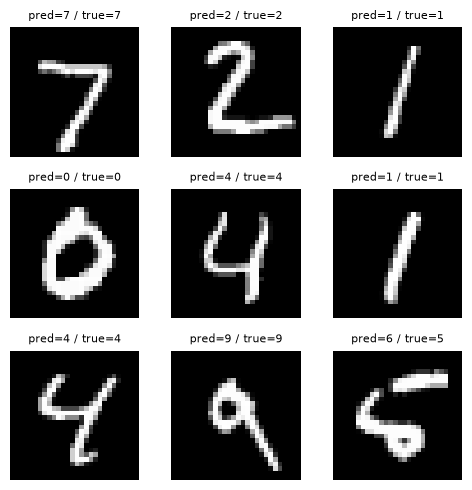

In [55]:
compact_net.eval()
x_batch, y_batch = next(iter(test_loader))
with torch.no_grad():
    preds = compact_net(x_batch.reshape(128, 1, 28, 28)).argmax(dim=1)

fig, axes = plt.subplots(3, 3, figsize=(5, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_batch[i].reshape(28, 28), cmap='gray')
    ax.set_title(f"pred={preds[i].item()} / true={y_batch[i].item()}", fontsize=8)
    ax.axis('off')
plt.tight_layout()
plt.show()

## ONNX

In [56]:
# the missing layer: argmax. The compiler's input contract is a float in [0, 1]
# (fixed INT8 encoding: scale 1/255, zero_point -128), so no /255 is exported.
class FullModel(nn.Module):

    def __init__(self, net):
        super().__init__()
        self.net = net
        self.eval()

    def forward(self, x):
        y = self.net(x)
        return torch.argmax(y)

full_model = FullModel(compact_net)

In [57]:
example = x_batch[3].reshape(1, 1, 28, 28)  # float in [0, 1]
y = full_model(example)
print(y)

tensor(0)


In [58]:
from pathlib import Path
import time

path = Path("./models") / str(int(time.time()))
path.mkdir(parents=True, exist_ok=True)

# use the full_model (includes argmax); export saves directly to file
fpath = path / "mnist_classifier.onnx"

example = x_batch[3].reshape(1, 1, 28, 28)  # float in [0, 1]

onnx_program = torch.onnx.export(
    full_model,
    example,
    str(fpath),
    export_params=True,
    opset_version=18,
    input_names=["input"],
    output_names=["pred"],
)

W1117 17:08:25.425000 29112 Lib\site-packages\torch\onnx\_internal\exporter\_registration.py:107] torchvision is not installed. Skipping torchvision::nms
W1117 17:08:25.429000 29112 Lib\site-packages\torch\onnx\_internal\exporter\_registration.py:107] torchvision is not installed. Skipping torchvision::roi_align
W1117 17:08:25.434000 29112 Lib\site-packages\torch\onnx\_internal\exporter\_registration.py:107] torchvision is not installed. Skipping torchvision::roi_pool
W1117 17:08:25.439000 29112 Lib\site-packages\torch\onnx\_internal\exporter\_registration.py:107] torchvision is not installed. Skipping torchvision::deform_conv2d


[torch.onnx] Obtain model graph for `FullModel([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `FullModel([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅


In [59]:
# Calibration set (training split only): float32 in [0, 1], shape (N, 1, 28, 28).
# X_train_full / X_test are already normalised to [0, 1] above.
rng = np.random.default_rng(0)
calib_idx = rng.choice(len(X_train_full), size=128, replace=False)
calibration_images = X_train_full[calib_idx].reshape(-1, 1, 28, 28).astype(np.float32)

# Held-out eval set (test split) so serial_infer-style checks can use the same file.
eval_idx = rng.choice(len(X_test), size=100, replace=False)
eval_images = X_test[eval_idx].reshape(-1, 1, 28, 28).astype(np.float32)
eval_labels = y_test[eval_idx]

# Wire-ready bytes: the compiler's fixed INT8 input encoding (scale 1/255,
# zero_point -128) maps a uint8 pixel p to int8 p - 128. tools/serial_infer.py
# sends these as-is, so no quantization happens on the host or the board.
eval_images_int8 = (np.rint(eval_images * 255).astype(np.int16) - 128).astype(np.int8)

np.savez_compressed(
    path / "calibration.npz",
    calibration_images=calibration_images,
    eval_images=eval_images,
    eval_images_int8=eval_images_int8,
    eval_labels=eval_labels,
)
print(f"Saved {path / 'calibration.npz'}")

Saved models\1794935303\calibration.npz
